In [14]:
!pip install -q "numpy>=2.0.0" "node2vec" "xgboost" "scikit-learn" "networkx" "pandas" --no-deps

import os
import random
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from node2vec import Node2Vec
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

In [15]:
# Environment Initialization
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

data_path = "/kaggle/input/datasets/akay6483/com-dblp-ungraph/com-dblp.ungraph.txt"
if not os.path.exists(data_path):
    dataset_dir = "/kaggle/input/com-dblp.ungraph"
    data_path = os.path.join(dataset_dir, os.listdir(dataset_dir)[0]) if os.path.exists(dataset_dir) else "com-dblp.ungraph.txt"

G_full = nx.read_edgelist(data_path, comments='#', nodetype=int, create_using=nx.Graph())


In [16]:
# Snowball BFS Sampling (3,000 nodes)
seed_node = max(dict(G_full.degree()), key=dict(G_full.degree()).get)
sampled_nodes, queue = {seed_node}, [seed_node]

while queue and len(sampled_nodes) < 3000:
    curr = queue.pop(0)
    for neighbor in G_full.neighbors(curr):
        if neighbor not in sampled_nodes:
            sampled_nodes.add(neighbor)
            queue.append(neighbor)
            if len(sampled_nodes) >= 3000:
                break

G = G_full.subgraph(max(nx.connected_components(G_full.subgraph(sampled_nodes)), key=len)).copy()
print(f"Sampled Graph | Nodes: {G.number_of_nodes():,} | Edges: {G.number_of_edges():,}")

Sampled Graph | Nodes: 3,000 | Edges: 22,157


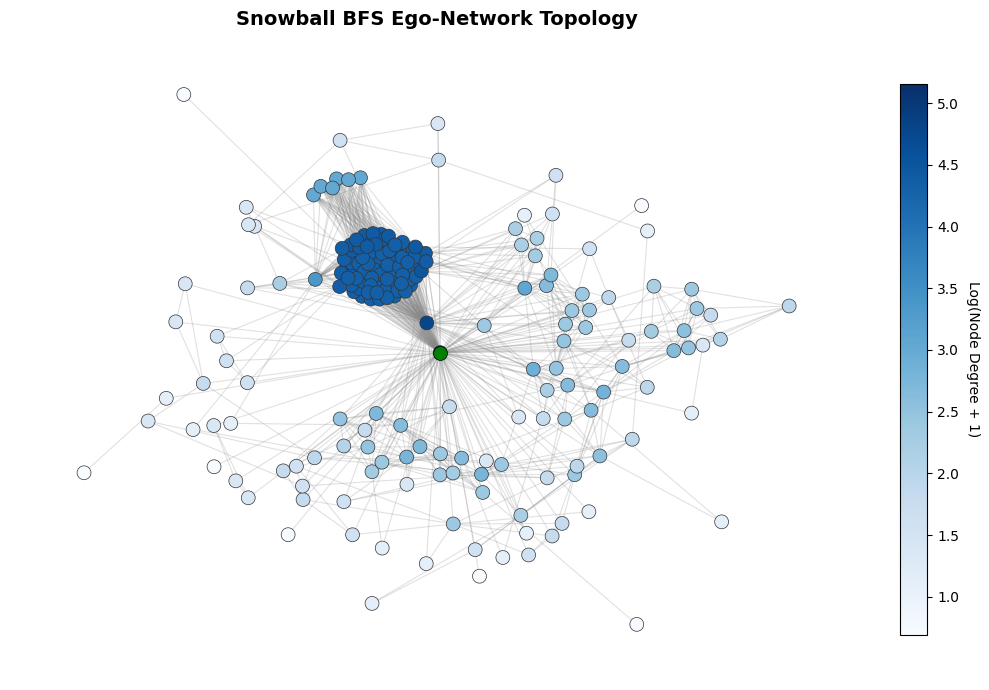

In [ ]:
# Visualization
sub_nodes = {seed_node}
queue = [seed_node]
while queue and len(sub_nodes) < 200:
    curr = queue.pop(0)
    for neighbor in G.neighbors(curr):
        if neighbor not in sub_nodes:
            sub_nodes.add(neighbor)
            queue.append(neighbor)
            if len(sub_nodes) >= 150: break

G_snowball = G.subgraph(sub_nodes)
pos = nx.spring_layout(G_snowball, seed=SEED, k=0.35)
log_degrees = np.log1p([G_snowball.degree(n) for n in G_snowball.nodes()])

plt.figure(figsize=(10, 7))
plt.title("Snowball BFS Ego-Network Topology", fontsize=14, fontweight='bold', pad=10)

# Clean, professional styling
scatter = nx.draw_networkx_nodes(
    G_snowball, pos, 
    node_size=[100 for n in G_snowball.nodes()],
    node_color=log_degrees, cmap='Blues', edgecolors='grey', linewidths=0.5
)
nx.draw_networkx_nodes(
    G_snowball, pos, nodelist=[seed_node], node_color='green', 
    node_size=100, edgecolors='black', linewidths=0.5
)
nx.draw_networkx_edges(G_snowball, pos, alpha=0.25, edge_color='grey', width=0.8)

cbar = plt.colorbar(scatter, fraction=0.03, pad=0.04)
cbar.set_label('Log(Node Degree + 1)', rotation=270, labelpad=15, fontsize=10)
plt.axis('off')
plt.tight_layout()
plt.show()

In [18]:
edges = list(G.edges())
random.shuffle(edges)

num_test = int(0.10 * len(edges))
test_pos_edges = edges[:num_test]
val_pos_edges = edges[num_test:num_test * 2]
train_pos_edges = edges[num_test * 2:]

G_train = G.copy()
G_train.remove_edges_from(test_pos_edges + val_pos_edges)
nodes_list = list(G.nodes())

def generate_train_negatives(num_samples):
    train_negs = set()
    while len(train_negs) < num_samples:
        u, v = random.choice(nodes_list), random.choice(nodes_list)
        if u != v and not G_train.has_edge(u, v):
            train_negs.add(tuple(sorted((u, v)))) 
    return list(train_negs)

def generate_ogb_negatives(pos_edges, num_candidates=100):
    eval_neg_dict = {}
    for u, v in pos_edges:
        u_nbrs = set(G.neighbors(u))  
        negs = []
        while len(negs) < num_candidates:
            w = random.choice(nodes_list)
            if w != u and w not in u_nbrs:
                negs.append((u, w))
        eval_neg_dict[(u, v)] = negs
    return eval_neg_dict

train_neg_edges = generate_train_negatives(len(train_pos_edges))
val_neg_dict = generate_ogb_negatives(val_pos_edges)
test_neg_dict = generate_ogb_negatives(test_pos_edges)

X_train_edges = train_pos_edges + train_neg_edges
y_train = np.array([1] * len(train_pos_edges) + [0] * len(train_neg_edges))

print(f"Train Edges: {len(train_pos_edges):,} pos / {len(train_neg_edges):,} neg")
print(f"Test Edges:  {len(test_pos_edges):,} pos / {len(test_pos_edges) * 100:,} neg candidates")

Train Edges: 17,727 pos / 17,727 neg
Test Edges:  2,215 pos / 221,500 neg candidates


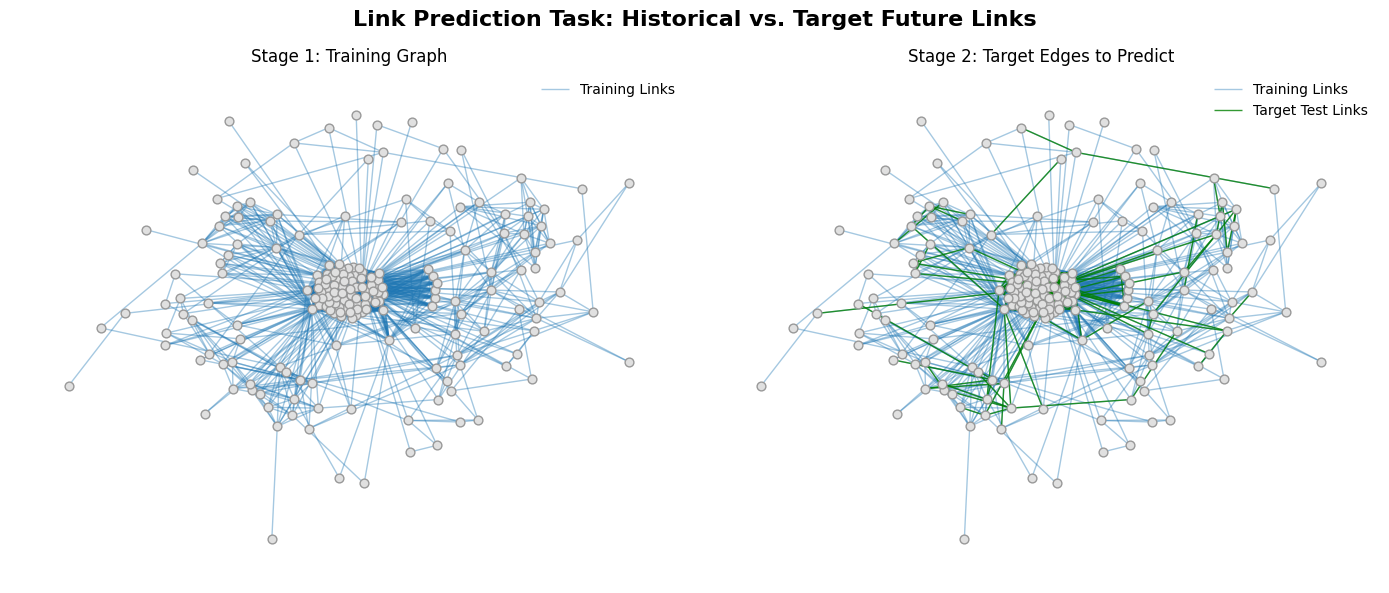

In [19]:
# Visualize the split task within the same 150-node scope
test_edges_set = {tuple(sorted(e)) for e in test_pos_edges}
sub_train_edges = list(G_snowball.edges())
sub_test_edges = [e for e in test_edges_set if e[0] in sub_nodes and e[1] in sub_nodes]

G_vis_task = nx.Graph()
G_vis_task.add_nodes_from(sub_nodes)
G_vis_task.add_edges_from(sub_train_edges + sub_test_edges)
pos_task = nx.spring_layout(G_vis_task, seed=SEED, k=0.35)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Link Prediction Task: Historical vs. Target Future Links", fontsize=16, fontweight='bold')

for i, ax in enumerate(axes):
    ax.axis('off')
    nx.draw_networkx_nodes(G_vis_task, pos_task, ax=ax, node_size=40, node_color='#E0E0E0', edgecolors='#999999')
    
    # Stage 1: Historical Training Edges[cite: 2]
    nx.draw_networkx_edges(
        G_vis_task, pos_task, ax=ax, edgelist=sub_train_edges, 
        edge_color='#1f77b4', width=1.0, alpha=0.4, label='Training Links'
    )
    # Stage 2: Target Test Edges overlay[cite: 2]
    if i == 1:
        nx.draw_networkx_edges(
            G_vis_task, pos_task, ax=ax, edgelist=sub_test_edges, 
            edge_color='green', width=1.0, alpha=0.8, label='Target Test Links'
        )
    ax.legend(loc='upper right', fontsize=10, frameon=False)
    ax.set_title(["Stage 1: Training Graph", "Stage 2: Target Edges to Predict"][i], fontsize=12)

plt.tight_layout()
plt.show()

In [20]:
n2v = Node2Vec(G_train, dimensions=32, walk_length=20, num_walks=30, p=0.5, q=2.0, workers=2, quiet=True)
n2v_model = n2v.fit(window=10, min_count=1)
print("Node2Vec training complete.")

Node2Vec training complete.


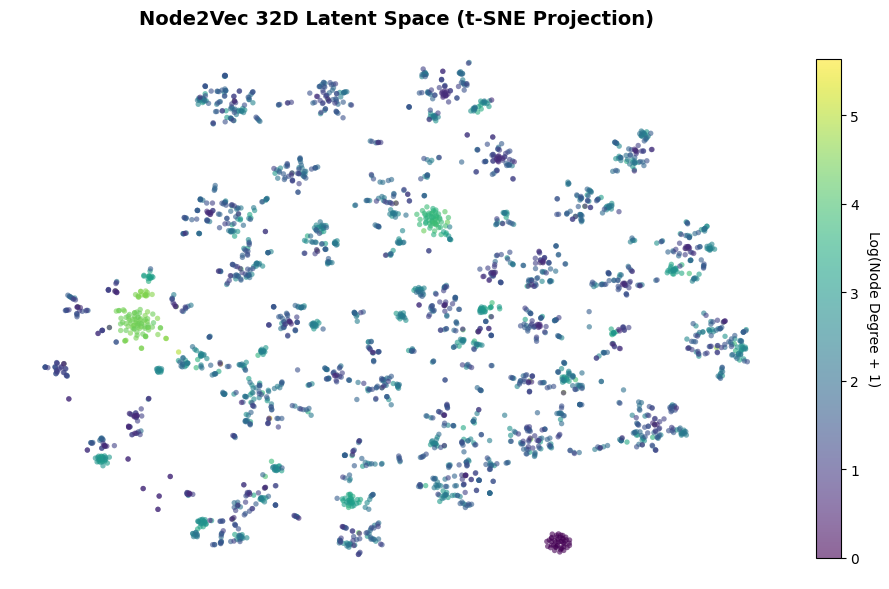

In [21]:
vocab_nodes = list(n2v_model.wv.index_to_key)
embeddings_32d = np.array([n2v_model.wv[node] for node in vocab_nodes])
log_degrees_32d = np.log1p([G_train.degree(int(n)) if G_train.has_node(int(n)) else 0 for n in vocab_nodes])

# Reduce to 2D
tsne = TSNE(n_components=2, init='pca', learning_rate='auto', random_state=SEED)
embs_2d = tsne.fit_transform(embeddings_32d)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    embs_2d[:, 0], embs_2d[:, 1], 
    c=log_degrees_32d, cmap='viridis', s=15, alpha=0.6, edgecolors='none'
)
cbar = plt.colorbar(scatter, fraction=0.03, pad=0.04)
cbar.set_label('Log(Node Degree + 1)', rotation=270, labelpad=15, fontsize=10)

plt.title("Node2Vec 32D Latent Space (t-SNE Projection)", fontsize=14, fontweight='bold', pad=10)
plt.axis('off')
plt.tight_layout()
plt.show()

In [22]:
def extract_heuristics(graph, edge_list):
    jacc = {(u, v): p for u, v, p in nx.jaccard_coefficient(graph, edge_list)}
    aa = {(u, v): p for u, v, p in nx.adamic_adar_index(graph, edge_list)}
    ra = {(u, v): p for u, v, p in nx.resource_allocation_index(graph, edge_list)}
    
    features = []
    for u, v in edge_list:
        features.append([
            jacc.get((u, v), jacc.get((v, u), 0.0)),
            aa.get((u, v), aa.get((v, u), 0.0)),
            ra.get((u, v), ra.get((v, u), 0.0)),
            len(list(nx.common_neighbors(graph, u, v))) if graph.has_node(u) and graph.has_node(v) else 0
        ])
    return np.array(features)

def extract_n2v(model, edge_list):
    return np.array([
        np.multiply(model.wv[str(u)], model.wv[str(v)]) if str(u) in model.wv and str(v) in model.wv else np.zeros(32)
        for u, v in edge_list
    ])

def evaluate_hits(pos_probs, neg_matrix, k_list=[10, 20, 50]):
    num_pos = len(pos_probs)
    return {f"Hits@{k}": round(np.sum([np.sum(neg_matrix[i] >= pos_probs[i]) + 1 <= k for i in range(num_pos)]) / num_pos, 4) for k in k_list}

def format_matrices(source, pos_edges, neg_dict, extractor_fn):
    return extractor_fn(source, pos_edges), np.array([extractor_fn(source, neg_dict[e]) for e in pos_edges])

# Generate Features
X_tr_heur = extract_heuristics(G_train, X_train_edges)
X_tr_n2v = extract_n2v(n2v_model, X_train_edges)

X_te_pos_heur, X_te_neg_heur = format_matrices(G_train, test_pos_edges, test_neg_dict, extract_heuristics)
X_te_pos_n2v, X_te_neg_n2v = format_matrices(n2v_model, test_pos_edges, test_neg_dict, extract_n2v)


In [23]:
# Train & Evaluate Models
params = {'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.1, 'random_state': SEED}

results = []
for name, X_tr, X_te_p, X_te_n in [("Classical Heuristics", X_tr_heur, X_te_pos_heur, X_te_neg_heur), 
                                   ("Node2Vec (32D)", X_tr_n2v, X_te_pos_n2v, X_te_neg_n2v)]:
    clf = XGBClassifier(**params).fit(X_tr, y_train)
    p_pos, p_neg = clf.predict_proba(X_te_p)[:, 1], np.array([clf.predict_proba(n)[:, 1] for n in X_te_n])
    
    y_flat = np.array([1] * len(p_pos) + [0] * p_neg.size)
    p_flat = np.concatenate([p_pos, p_neg.flatten()])
    
    results.append({"Model": name, "ROC-AUC": round(roc_auc_score(y_flat, p_flat), 4), **evaluate_hits(p_pos, p_neg)})

print("\n=== OGB Benchmark Results ===")
print(pd.DataFrame(results).to_string(index=False))


=== OGB Benchmark Results ===
               Model  ROC-AUC  Hits@10  Hits@20  Hits@50
Classical Heuristics   0.9660   0.9391   0.9400   0.9404
      Node2Vec (32D)   0.9676   0.9246   0.9499   0.9824
